In [25]:

# Import Neccessory Libraries
# For Data Computation
import numpy as np
import pandas as pd
# For Visualization
import matplotlib.pyplot as plt
import seaborn as sns
# Logging Library
import logging
logging.basicConfig(level = logging.INFO,
                    filename = 'model.log',
                    filemode = 'w',
                    format = "%(asctime)s - %(message)s - %(levelname)s",
                    force = True)
# Filter warning messages
import warnings
warnings.filterwarnings(action = 'ignore')
# Set theme
sns.set_theme(style = 'darkgrid')

In [26]:
# Step1: Data Ingestion

try:
  filepath = 'C:\python_programing\Titanic-Dataset.csv'
  df = pd.read_csv(filepath)
  df.sample(frac = 0.2)
except FileNotFoundError as e:
  logging.error(e)
except Exception as e:
  logging.error(e)
else:
  logging.info('Data Ingestion Successful')

In [27]:
# Checking Descriptive Stats
numerical_col = df.select_dtypes(exclude = 'object').columns
categorical_col = df.select_dtypes(include = 'object').columns

from collections import OrderedDict
stats = []
for i in numerical_col:
  numerical_stats = OrderedDict({
      'Feature':i,
      'Maximum':df[i].max(),
      'Minimum':df[i].min(),
      'Mean':df[i].mean(),
      'Median':df[i].median(),
      'Unique_Values':df[i].nunique(),
      '% of Missing Values':(df[i].isnull().sum()/df.shape[0])*100,
      'Null Values':df[i].isnull().sum(),
      'Q1':df[i].quantile(0.25),
      'Q3':df[i].quantile(0.75),
      'IQR': df[i].quantile(0.75) - df[i].quantile(0.25),
      'Std':df[i].std(),
      'Skewness':df[i].skew(),
      'Kurtosis':df[i].kurtosis()
  })
  stats.append(numerical_stats)
  report = pd.DataFrame(stats)

report

,Feature,Maximum,Minimum,Mean,Median,Unique_Values,% of Missing Values,Null Values,Q1,Q3,IQR,Std,Skewness,Kurtosis
0,PassengerId,891.0000,1.00,446.000000,446.0000,891,0.00000,0,223.5000,668.5,445.0000,257.353842,0.000000,-1.200000
1,Survived,1.0000,0.00,0.383838,0.0000,2,0.00000,0,0.0000,1.0,1.0000,0.486592,0.478523,-1.775005
2,Pclass,3.0000,1.00,2.308642,3.0000,3,0.00000,0,2.0000,3.0,1.0000,0.836071,-0.630548,-1.280015
3,Age,80.0000,0.42,29.699118,28.0000,88,19.86532,177,20.1250,38.0,17.8750,14.526497,0.389108,0.178274
4,SibSp,8.0000,0.00,0.523008,0.0000,7,0.00000,0,0.0000,1.0,1.0000,1.102743,3.695352,17.880420
5,Parch,6.0000,0.00,0.381594,0.0000,7,0.00000,0,0.0000,0.0,0.0000,0.806057,2.749117,9.778125
6,Fare,512.3292,0.00,32.204208,14.4542,248,0.00000,0,7.9104,31.0,23.0896,49.693429,4.787317,33.398141


In [28]:
# Saving report to csv
report.to_csv('report.csv')

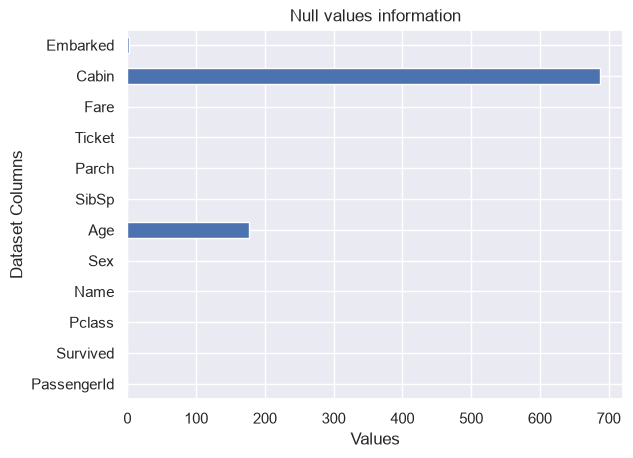

In [29]:
# Checking Null values in dataset using graphical method
df.isnull().sum().plot(kind = 'barh')
plt.title('Null values information')
plt.xlabel('Values')
plt.ylabel('Dataset Columns')
plt.show()

<Axes: >

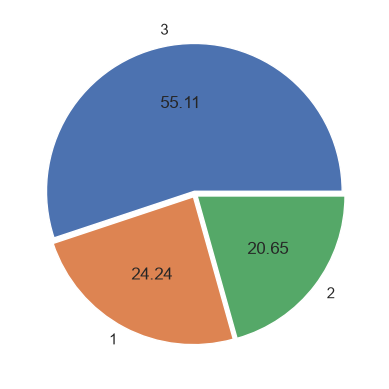

In [30]:
df['Pclass'].value_counts().plot(kind = 'pie',
                                 autopct = "%.2f",
                                 explode = [0.02,0.02,0.02])

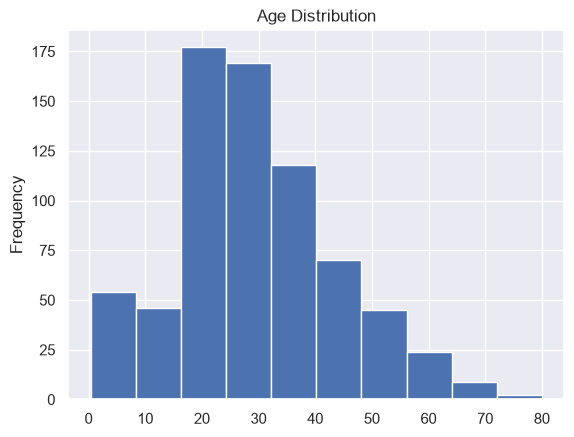

In [31]:
df['Age'].plot(kind = 'hist')
plt.title('Age Distribution')
plt.show()

In [32]:
filepath  = 'C:\python_programing\Titanic-Dataset.csv'
df = pd.read_csv(filepath)
df



,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [33]:
# segreagate the data based on embarkded i.e.southampton 's'   
southampton_data = df[df['embarked'] == 's']

KeyError: 'embarked'

In [35]:
southampton_data['Sex'] == 'female'
southampton_data

NameError: name 'southampton_data' is not defined

In [42]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [50]:
pd.crosstab(index = [df['Pclass'],df['Embarked']],
            columns = [df['Sex'],df['Survived']], 
            margins = True)

Sex             female      male       All
Survived             0    1    0    1     
Pclass Embarked                           
1      C             1   42   25   17   85
       Q             0    1    1    0    2
       S             2   46   51   28  127
2      C             0    7    8    2   17
       Q             0    2    1    0    3
       S             6   61   82   15  164
3      C             8   15   33   10   66
       Q             9   24   36    3   72
       S            55   33  231   34  353
All                 81  231  468  109  889

<Axes: xlabel='Survived'>

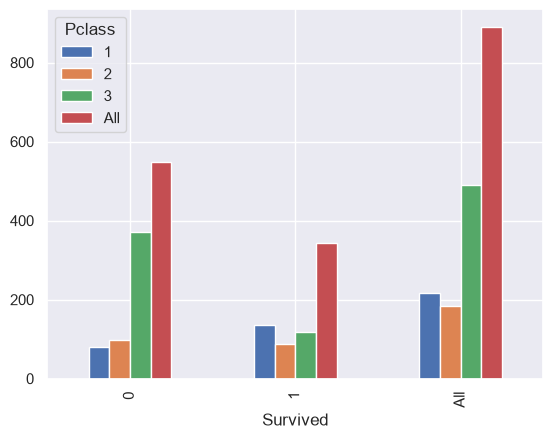

In [53]:
a = pd.crosstab(index = df['Survived'],
                columns = df['Pclass'],
                margins = True )
                
                
a.plot(kind = 'bar')              

In [ ]:
queenstowm

In [ ]:
chelsberg

In [12]:
import numpy as np 
import pandas as pd 

In [18]:
# prepare dataset 

df = pd.DataFrame({
    'SrNo':[1,2,3,4,5,6,7,8,9,10],
    'Name':[np.nan,'A','B','C','D','E','F','G','H',np.nan],
    'Gender':['M','F','F','M','F','M','M','F','M','F'],
    'Age':[19,np.nan,np.nan,np.nan,np.nan,18,19,20,22,23],
    'Salary':[1000,4000,7000,9000,10000,np.nan,np.nan,9000,8000,67000]
})
df

    
    



,SrNo,Name,Gender,Age,Salary
0,1,NaN,M,19.0,1000.0
1,2,A,F,NaN,4000.0
2,3,B,F,NaN,7000.0
3,4,C,M,NaN,9000.0
4,5,D,F,NaN,10000.0
5,6,E,M,18.0,NaN
6,7,F,M,19.0,NaN
7,8,G,F,20.0,9000.0
8,9,H,M,22.0,8000.0
9,10,NaN,F,23.0,67000.0


In [24]:
# Checking Descriptive Stats

numerical_col = df.select_dtypes(exclude = 'object').columns
categorical_col = df.select_dtypes(include = 'object').columns

from collections import OrderedDict
stats = []
for i in numerical_col:
    numerical_stats = OrderedDict({
        'Feature':i,
        'Missing_Values': df[i].isnull().sum() / len(df[i]) * 100,
        'Minimum': df[i].min(),
        'Maximum': df[i].max(),
        'Mean': df[i].mean(),
        'Median': df[i].median(),
        'Q1': df[i].quantile(0.25),
        'Q3': df[i].quantile(0.75),
        'IOR': df[i].quantile(0.75) - df[i].quantile(0.25),
        'Std': df[i].std(),
        'Skewness': df[i].skew(),
        'Kurtosis': df[i].kurt()
    })
    stats.append(numerical_stats)
    report = pd.DataFrame(stats)
report

C:\Users\Vishnu\AppData\Local\Temp\ipykernel_11036\2144502317.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_col = df.select_dtypes(include = 'object').columns


,Feature,Missing_Values,Minimum,Maximum,Mean,Median,Q1,Q3,IOR,Std,Skewness,Kurtosis
0,SrNo,0.0,1.0,10.0,5.500000,5.5,3.25,7.75,4.5,3.027650,0.000000,-1.200000
1,Age,40.0,18.0,23.0,20.166667,19.5,19.00,21.50,2.5,1.940790,0.638368,-1.242854
2,Salary,20.0,1000.0,67000.0,14375.000000,8500.0,6250.00,9250.00,3000.0,21473.821271,2.715634,7.547427


In [36]:
# create copy of df 
data = df.copy()
# using fillna 
data['Salary'] = data['Salary'].fillna(data['Salary'].median())
data['Age'] = data['Age'].fillna(data['Age'].mean())
data['Name'] = data['Name'].fillna(data['Name'].mode()[0])
data

,SrNo,Name,Gender,Age,Salary
0,1,A,M,19.000000,1000.0
1,2,A,F,20.166667,4000.0
2,3,B,F,20.166667,7000.0
3,4,C,M,20.166667,9000.0
4,5,D,F,20.166667,10000.0
5,6,E,M,18.000000,8500.0
6,7,F,M,19.000000,8500.0
7,8,G,F,20.000000,9000.0
8,9,H,M,22.000000,8000.0
9,10,A,F,23.000000,67000.0


In [41]:
# using SimpleImputer()

data1 = df.copy()

data1 = data1.drop(columns = ['Name','Gender'])

from sklearn.impute import SimpleImputer 
impute = SimpleImputer(strategy = 'median')

data2 = impute.fit_transform(data1)
data2



array([[1.00e+00, 1.90e+01, 1.00e+03],
       [2.00e+00, 1.95e+01, 4.00e+03],
       [3.00e+00, 1.95e+01, 7.00e+03],
       [4.00e+00, 1.95e+01, 9.00e+03],
       [5.00e+00, 1.95e+01, 1.00e+04],
       [6.00e+00, 1.80e+01, 8.50e+03],
       [7.00e+00, 1.90e+01, 8.50e+03],
       [8.00e+00, 2.00e+01, 9.00e+03],
       [9.00e+00, 2.20e+01, 8.00e+03],
       [1.00e+01, 2.30e+01, 6.70e+04]])

<Axes: >

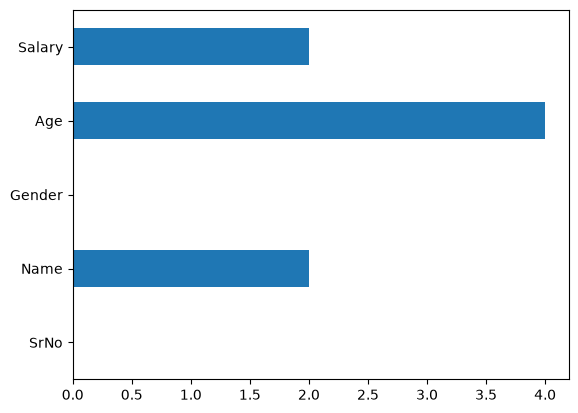

In [44]:
df.isna().sum().plot(kind = 'barh')


<Axes: >

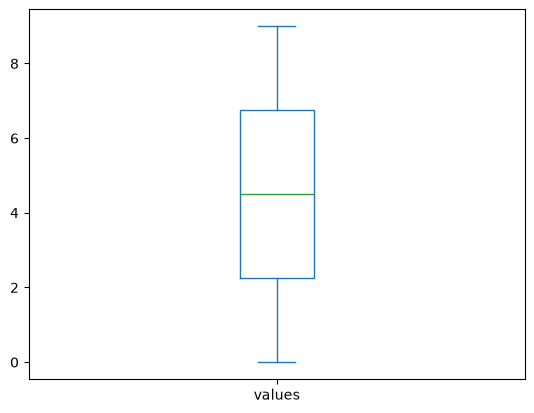

In [45]:
data = pd.DataFrame({'values' :[0,1,2,3,4,5,6,7,8,9]})
data.plot(kind = 'box')


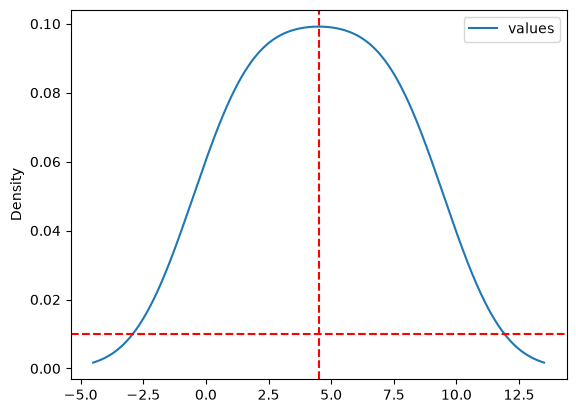

In [52]:
import matplotlib.pyplot as plt 
data.plot(kind = 'kde')
plt.axvline(4.5,linestyle = '--',color = 'red')
plt.axhline(0.01,linestyle = '--',color = 'red')



In [46]:
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1 
LW = Q1 - 1.5*IQR 
UW = Q3 + 1.5*IQR 




In [48]:
print(f'Q1: {Q1}')
print(f'Q3: {Q3}')
print(f'IQR: {IQR}')
print(f'LW: {LW}')
print(f'UW: {UW}')


Q1: values    2.25
Name: 0.25, dtype: float64
Q3: values    6.75
Name: 0.75, dtype: float64
IQR: values    4.5
dtype: float64
LW: values   -4.5
dtype: float64
UW: values    13.5
dtype: float64
